# Лабораторная работа №11. CNN: размерности, receptive field и backpropagation

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №11».

**Данные.** FashionMNIST — 10 классов одежды, серые картинки 28×28. Скачивается `torchvision` при первом запуске в `data/datasets/` (папка не хранится в git). Для скорости на CPU берётся подвыборка: 20 000 картинок для обучения, 5 000 для проверки.

## 1. О чём эта работа

### Знакомый пример

Телефон сортирует фотографии по альбомам «еда», «документы», «животные». За этим стоит свёрточная нейросеть: она получает картинку и выдаёт 10 (или 1000) чисел — «насколько это похоже на каждый класс».

### Основная идея

В лабораторной 3 мы прикладывали к картинке ядро 3×3 с заранее заданными весами (размытие, поиск границ). **Свёрточный слой** делает то же самое, только веса ядер не задаются человеком, а подбираются при обучении. Слоёв много: первые находят границы и пятна, следующие — их сочетания (углы, текстуры), последние — части предметов.

Обучение: показываем сети картинку, сравниваем её ответ с правильным, считаем число «насколько ошиблась» — **loss**. Затем для каждого веса вычисляем, в какую сторону его сдвинуть, чтобы loss уменьшился (это **градиент**), и чуть-чуть сдвигаем. Повторяем тысячи раз.

Прежде чем запускать сеть, полезно уметь на бумаге ответить на три вопроса: какого размера будут данные после каждого слоя, сколько в сети обучаемых чисел и какую часть картинки «видит» один выходной нейрон.

### Понятия

- **Тензор** — многомерный массив. Картинка: `C×H×W` (каналы, высота, ширина). Пачка картинок (**batch**): `B×C×H×W`.
- **Свёрточный слой** `Conv`: $C_{out}$ ядер размера $K\times K$, каждое смотрит на все $C_{in}$ входных каналов. Каждое ядро даёт одну выходную карту.
- **Stride** $S$ — шаг, с которым ядро едет по картинке. $S=2$ уменьшает карту вдвое.
- **Padding** $P$ — сколько нулей приклеить по краям, чтобы ядро могло встать на крайние пиксели.
- **Pooling** — уменьшение карты: из каждого окна (обычно 2×2) берётся максимум. Параметров не имеет.
- **Bias** — одно дополнительное число на каждое ядро, прибавляемое к результату.
- **Receptive field** (рецептивное поле) — участок входной картинки, от которого зависит один элемент на выходе слоя.
- **Logits** $z$ — «сырые» выходы сети, по одному числу на класс, любые по величине и знаку.
- **Softmax** превращает logits в вероятности: положительные числа с суммой 1.
- **Cross-entropy** (CE) — loss для классификации: минус логарифм вероятности, которую сеть дала правильному классу. Уверенный правильный ответ — loss около 0; уверенный неправильный — большой loss.
- **Chain rule** (правило цепочки) — производная сложной функции равна произведению производных её звеньев. **Backpropagation** — применение этого правила ко всей сети, от loss назад к весам.

### Формулы

Размер выхода свёрточного (и pooling) слоя:

$$H_{out}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1$$

Откуда она: в строке длиной $H+2P$ ядро длиной $K$ может сдвинуться на $H+2P-K$ позиций; шагом $S$ это $\lfloor\cdot/S\rfloor$ шагов, плюс начальная позиция.

Число параметров свёрточного слоя:

$$\text{Params}=C_{out}\,(C_{in}K_hK_w+1)$$

Одно ядро — $C_{in}K_hK_w$ весов и один bias; ядер $C_{out}$.

Softmax и cross-entropy ($y$ — номер правильного класса):

$$p_i=\frac{e^{z_i}}{\sum_je^{z_j}},\qquad L=-\ln p_y,\qquad \frac{\partial L}{\partial z}=p-y_{onehot}$$

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

SEED = 0
N_TRAIN, N_VAL = 20000, 5000
BATCH = 128
EPOCHS = 4
LR = 1e-3
DATA_DIR = "data/datasets"
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED); np.random.seed(SEED)
print("torch", torch.__version__, "| device:", device)

torch 2.14.1+cpu | device: cpu


## 2. Вопрос 1 — размеры и число параметров

> Вход 64×64×3. Conv K=5, S=2, P=2, Cout=16, затем MaxPool K=2, S=2. Найдите shapes и число параметров Conv.

**Conv.** По формуле для высоты (ширина считается так же):

$$H_{out}=\left\lfloor\frac{64+2\cdot2-5}{2}\right\rfloor+1=\left\lfloor\frac{63}{2}\right\rfloor+1=31+1=32$$

Число каналов на выходе равно числу ядер: 16. Выход — **32×32×16**.

**MaxPool** — та же формула с $P=0$: $\lfloor(32-2)/2\rfloor+1=15+1=16$. Каналы не меняются. Выход — **16×16×16**.

**Параметры Conv.** Одно ядро смотрит на 3 канала окном 5×5: $3\cdot5\cdot5=75$ весов, плюс bias — 76. Ядер 16: $16\cdot76=1216$.

У MaxPool параметров нет.

**На что обратить внимание.** Число параметров свёрточного слоя не зависит от размера картинки — только от размера ядра и числа каналов. Картинка 64×64 или 1024×1024 — те же 1216 чисел. Число значений в данных при этом изменилось: было $64\cdot64\cdot3=12288$, стало $16\cdot16\cdot16=4096$.

In [2]:
def conv_out(h, k, s=1, p=0):
    return (h + 2 * p - k) // s + 1

def conv_params(c_in, c_out, k):
    return c_out * (c_in * k * k + 1)

h1 = conv_out(64, 5, 2, 2); h2 = conv_out(h1, 2, 2)
print(f"вручную: Conv → {h1}×{h1}×16, Pool → {h2}×{h2}×16, params = {conv_params(3, 16, 5)}")

conv = nn.Conv2d(3, 16, kernel_size=5, stride=2, padding=2); pool = nn.MaxPool2d(2, 2)
x = torch.zeros(1, 3, 64, 64)
print("PyTorch (B×C×H×W): Conv →", tuple(conv(x).shape), " Pool →", tuple(pool(conv(x)).shape), " params =", sum(p.numel() for p in conv.parameters()))
print("  веса:", tuple(conv.weight.shape), "= C_out × C_in × K × K;  bias:", tuple(conv.bias.shape))

вручную: Conv → 32×32×16, Pool → 16×16×16, params = 1216
PyTorch (B×C×H×W): Conv → (1, 16, 32, 32)  Pool → (1, 16, 16, 16)  params = 1216
  веса: (16, 3, 5, 5) = C_out × C_in × K × K;  bias: (16,)


**Итог вопроса 1:** Conv → 32×32×16, Pool → 16×16×16, параметров 1216.

PyTorch хранит каналы первыми (`16×32×32`), методичка пишет последними (`32×32×16`) — это одно и то же.

## 3. Вопрос 2 — receptive field, softmax, CE и градиент

> Для Conv3 s1 → Conv3 s1 → Pool2 s2 → Conv3 s1 найдите receptive field. Затем для logits [1,2,0] и истинного второго класса найдите softmax, CE и gradient p−y.

### Receptive field

Отслеживаем два числа: $r$ — размер поля в пикселях входа, и $j$ («jump») — расстояние во входных пикселях между соседними элементами текущей карты. На входе $r=1$, $j=1$. Каждый слой с ядром $K$ и шагом $S$:

$$r_{new}=r+(K-1)\cdot j,\qquad j_{new}=j\cdot S$$

Смысл: ядро размера $K$ захватывает $K$ соседних элементов текущей карты, то есть добавляет $K-1$ шагов по $j$ пикселей.

| слой | K | S | $r$ | $j$ |
|---|---|---|---|---|
| вход | | | 1 | 1 |
| Conv3 s1 | 3 | 1 | $1+2\cdot1=3$ | 1 |
| Conv3 s1 | 3 | 1 | $3+2\cdot1=5$ | 1 |
| Pool2 s2 | 2 | 2 | $5+1\cdot1=6$ | 2 |
| Conv3 s1 | 3 | 1 | $6+2\cdot2=10$ | 2 |

Receptive field — **10×10**. Последняя свёртка добавила 4 пикселя, а не 2: после pooling соседние элементы карты отстоят на 2 входных пикселя. Stride ускоряет рост поля для всех следующих слоёв.

### Softmax, cross-entropy, градиент

Logits $z=[1,2,0]$, правильный класс — второй.

**Softmax.** $e^1\approx2.718$, $e^2\approx7.389$, $e^0=1$; сумма $\approx11.107$.

$$p\approx\left[\frac{2.718}{11.107},\ \frac{7.389}{11.107},\ \frac{1}{11.107}\right]=[0.2447,\ 0.6652,\ 0.0900]$$

**Cross-entropy.** $L=-\ln p_2=-\ln0.6652\approx0.4076$.

**Градиент.** $y=[0,1,0]$; $p-y\approx[0.2447,\ -0.3348,\ 0.0900]$.

**Смысл градиента.** Шаг обучения сдвигает logits *против* градиента. У правильного класса градиент отрицательный — его logit вырастет. У остальных положительный — их logits уменьшатся, причём тем сильнее, чем больше вероятности им ошибочно дано. Сумма компонент равна нулю: сколько «отняли» у неправильных, столько «добавили» правильному. Когда сеть уверена и права ($p_y\to1$), градиент стремится к нулю — учиться нечему.

### Откуда берётся $p-y$

$L=-\ln p_y=-z_y+\ln\sum_je^{z_j}$ (логарифм дроби — разность логарифмов). Дифференцируем по $z_i$:

- первое слагаемое: $-1$, если $i=y$, иначе 0, то есть $-y_i$;
- второе: $\dfrac{e^{z_i}}{\sum_je^{z_j}}=p_i$.

Итого $\partial L/\partial z_i=p_i-y_i$.

In [3]:
def receptive_field(layers):
    r, j = 1, 1
    for name, k, s in layers:
        r, j = r + (k - 1) * j, j * s
        print(f"  {name:10} K={k} S={s}: r = {r:2d}, j = {j}")
    return r

print("receptive field по формуле:")
rf = receptive_field([("Conv3 s1", 3, 1), ("Conv3 s1", 3, 1), ("Pool2 s2", 2, 2), ("Conv3 s1", 3, 1)])

# численная проверка: от каких входных пикселей зависит один выходной элемент
net = nn.Sequential(nn.Conv2d(1, 1, 3), nn.Conv2d(1, 1, 3), nn.AvgPool2d(2, 2), nn.Conv2d(1, 1, 3))
for p_ in net.parameters(): nn.init.constant_(p_, 1.0)
inp = torch.ones(1, 1, 32, 32, requires_grad=True)
out = net(inp); out[0, 0, 5, 5].backward()
nz = (inp.grad[0, 0] != 0).nonzero()
size = (nz.max(0).values - nz.min(0).values + 1).tolist()
print(f"численно (ненулевой градиент по входу): {size[0]}×{size[1]}")

z = np.array([1.0, 2.0, 0.0]); target = 1
e = np.exp(z); p = e / e.sum()
print(f"\nexp(z) = {e}, сумма = {e.sum():.4f}")
print("softmax p =", p, " сумма =", p.sum())
print("CE = −ln p[target] =", round(-np.log(p[target]), 4))
grad = p.copy(); grad[target] -= 1.0
print("gradient p − y =", grad, " сумма =", round(grad.sum(), 12))

zt = torch.tensor(z, requires_grad=True)
loss_t = nn.functional.cross_entropy(zt[None], torch.tensor([target])); loss_t.backward()
print("PyTorch: CE =", round(loss_t.item(), 4), " autograd grad =", zt.grad.numpy())

receptive field по формуле:
  Conv3 s1   K=3 S=1: r =  3, j = 1
  Conv3 s1   K=3 S=1: r =  5, j = 1
  Pool2 s2   K=2 S=2: r =  6, j = 2
  Conv3 s1   K=3 S=1: r = 10, j = 2
численно (ненулевой градиент по входу): 10×10

exp(z) = [2.7183 7.3891 1.    ], сумма = 11.1073
softmax p = [0.2447 0.6652 0.09  ]  сумма = 1.0
CE = −ln p[target] = 0.4076
gradient p − y = [ 0.2447 -0.3348  0.09  ]  сумма = 0.0
PyTorch: CE = 0.4076  autograd grad = [ 0.2447 -0.3348  0.09  ]


**Итог вопроса 2:** receptive field 10×10; $p\approx[0.2447, 0.6652, 0.0900]$, $L\approx0.408$, градиент $\approx[0.2447,-0.3348,0.0900]$ — совпадает с autograd.

## 4. Задание 3 — код и эксперимент

### Шаг 1. Датасет

train: (20000, 1, 28, 28)  val: (5000, 1, 28, 28)
классы: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
объектов на класс в train: [2042, 1948, 2041, 1946, 1944, 2049, 2071, 1988, 2018, 1953]


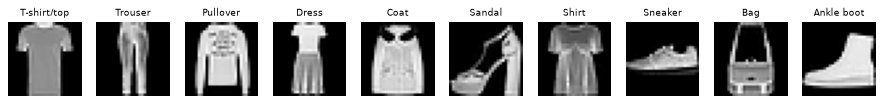

In [4]:
tf = torchvision.transforms.ToTensor()
train_full = torchvision.datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=tf)
val_full = torchvision.datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=tf)
CLASSES = train_full.classes

g = torch.Generator().manual_seed(SEED)
tr_idx = torch.randperm(len(train_full), generator=g)[:N_TRAIN]
va_idx = torch.randperm(len(val_full), generator=g)[:N_VAL]
# картинки маленькие — держим всё в памяти одним тензором, значения 0..1
Xtr = (train_full.data[tr_idx].float() / 255)[:, None]; ytr = train_full.targets[tr_idx]
Xva = (val_full.data[va_idx].float() / 255)[:, None]; yva = val_full.targets[va_idx]
print("train:", tuple(Xtr.shape), " val:", tuple(Xva.shape))
print("классы:", CLASSES)
print("объектов на класс в train:", torch.bincount(ytr).tolist())

fig, ax = plt.subplots(1, 10, figsize=(14, 1.8))
for a_, k in zip(ax, range(10)):
    a_.imshow(Xtr[(ytr == k).nonzero()[0, 0], 0]); a_.set_title(CLASSES[k], fontsize=8); a_.axis("off")
plt.show()

### Шаги 2–4. Архитектура, ручная таблица shapes/params, сверка с PyTorch

Три свёрточных блока. Таблица сначала заполняется **формулами** (функции `conv_out` и `conv_params` из вопроса 1), и только потом сравнивается с тем, что реально получилось в PyTorch.

| блок | слой | что делает |
|---|---|---|
| 1 | Conv 1→16, K=3, P=1; ReLU; MaxPool 2 | 28×28 → 14×14 |
| 2 | Conv 16→32, K=3, P=1; ReLU; MaxPool 2 | 14×14 → 7×7 |
| 3 | Conv 32→64, K=3, P=1; ReLU | 7×7 |
| голова | Flatten; Linear → 10 | вектор → 10 logits |

`ReLU` — функция $\max(0,x)$, применяется поэлементно: без такой нелинейности любая цепочка свёрток была бы эквивалентна одной свёртке. `Flatten` вытягивает карту `64×7×7` в вектор длины 3136. `Linear` — полносвязный слой: каждый из 10 выходов — взвешенная сумма всех 3136 входов плюс bias.

In [5]:
spec = [("conv1", 1, 16), ("pool1", None, None), ("conv2", 16, 32), ("pool2", None, None), ("conv3", 32, 64)]
h, c = 28, 1
manual = []
for name, cin, cout in spec:
    if name.startswith("conv"):
        h_new = conv_out(h, 3, 1, 1); manual.append((name, (c, h, h), (cout, h_new, h_new), conv_params(cin, cout, 3))); c = cout
    else:
        h_new = conv_out(h, 2, 2); manual.append((name, (c, h, h), (c, h_new, h_new), 0))
    h = h_new
flat = c * h * h
manual.append(("fc", (flat,), (10,), flat * 10 + 10))

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1); self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1); self.pool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc = nn.Linear(64 * 7 * 7, 10)
        self.relu = nn.ReLU()
    def forward(self, x, return_shapes=False):
        shapes = {}
        x = self.relu(self.conv1(x)); shapes["conv1"] = tuple(x.shape[1:])
        x = self.pool1(x); shapes["pool1"] = tuple(x.shape[1:])
        x = self.relu(self.conv2(x)); shapes["conv2"] = tuple(x.shape[1:])
        x = self.pool2(x); shapes["pool2"] = tuple(x.shape[1:])
        x = self.relu(self.conv3(x)); shapes["conv3"] = tuple(x.shape[1:])
        x = self.fc(x.flatten(1)); shapes["fc"] = tuple(x.shape[1:])
        return (x, shapes) if return_shapes else x

torch.manual_seed(SEED)
model = SmallCNN().to(device)
_, real_shapes = model(Xtr[:2].to(device), return_shapes=True)

print(f"{'Слой':7}{'Input shape':>16}{'Output (ручной)':>18}{'Output (PyTorch)':>19}{'Ручные params':>15}{'PyTorch params':>16}")
total_manual = 0
for name, in_s, out_s, n_par in manual:
    layer = getattr(model, name)
    n_torch = sum(p.numel() for p in layer.parameters())
    total_manual += n_par
    assert out_s == real_shapes[name] and n_par == n_torch
    print(f"{name:7}{str(in_s):>16}{str(out_s):>18}{str(real_shapes[name]):>19}{n_par:15d}{n_torch:16d}")
total_torch = sum(p.numel() for p in model.parameters())
print(f"{'итого':7}{'':>16}{'':>18}{'':>19}{total_manual:15d}{total_torch:16d}")
print(f"доля параметров в полносвязном слое: {100 * manual[-1][3] / total_torch:.1f} %")
print("receptive field последнего свёрточного слоя:")
_ = receptive_field([("conv1", 3, 1), ("pool1", 2, 2), ("conv2", 3, 1), ("pool2", 2, 2), ("conv3", 3, 1)])

Слой        Input shape   Output (ручной)   Output (PyTorch)  Ручные params  PyTorch params
conv1       (1, 28, 28)      (16, 28, 28)       (16, 28, 28)            160             160
pool1      (16, 28, 28)      (16, 14, 14)       (16, 14, 14)              0               0
conv2      (16, 14, 14)      (32, 14, 14)       (32, 14, 14)           4640            4640
pool2      (32, 14, 14)        (32, 7, 7)         (32, 7, 7)              0               0
conv3        (32, 7, 7)        (64, 7, 7)         (64, 7, 7)          18496           18496
fc              (3136,)             (10,)              (10,)          31370           31370
итого                                                                 54666           54666
доля параметров в полносвязном слое: 57.4 %
receptive field последнего свёрточного слоя:
  conv1      K=3 S=1: r =  3, j = 1
  pool1      K=2 S=2: r =  4, j = 2
  conv2      K=3 S=1: r =  8, j = 2
  pool2      K=2 S=2: r = 10, j = 4
  conv3      K=3 S=1: r = 18, j

Ручной расчёт и PyTorch совпали по каждому слою. Больше половины параметров сидит в одном полносвязном слое: он соединяет каждый из 3136 входов с каждым из 10 выходов, тогда как свёртки используют одни и те же маленькие ядра по всей картинке.

### Шаги 5–7. Один batch: stable softmax и cross-entropy в NumPy

**Зачем вычитать максимум.** $e^{z}$ растёт очень быстро: $e^{710}$ уже не помещается в `float64` и превращается в `inf`, после чего `inf/inf = nan`. Но softmax не меняется, если из всех logits вычесть одно и то же число $c$:

$$\frac{e^{z_i-c}}{\sum_je^{z_j-c}}=\frac{e^{z_i}e^{-c}}{e^{-c}\sum_je^{z_j}}=\frac{e^{z_i}}{\sum_je^{z_j}}$$

Берём $c=\max z$: тогда наибольший показатель равен 0, $e^0=1$, остальные показатели отрицательные — переполнение невозможно.

In [6]:
def softmax_stable(z):
    z_shift = z - z.max(axis=1, keepdims=True)          # вычитаем максимум в каждой строке
    e = np.exp(z_shift)
    return e / e.sum(axis=1, keepdims=True)

def cross_entropy_np(z, targets):
    p = softmax_stable(z)
    return -np.log(p[np.arange(len(targets)), targets]).mean(), p

xb, yb = Xtr[:BATCH].to(device), ytr[:BATCH].to(device)
logits = model(xb)                                      # сеть ещё не обучена
z_np, y_np = logits.detach().cpu().numpy().astype(np.float64), yb.cpu().numpy()

loss_np, p_np = cross_entropy_np(z_np, y_np)
loss_torch = nn.CrossEntropyLoss()(logits, yb).item()
print("logits:", z_np.shape, " диапазон:", z_np.min().round(3), "…", z_np.max().round(3))
print(f"CE NumPy = {loss_np:.6f}, CE PyTorch = {loss_torch:.6f}, |Δ| = {abs(loss_np - loss_torch):.2e}")
print(f"для необученной сети ожидаем ≈ ln(10) = {np.log(10):.4f} (все 10 классов равновероятны)")

logits: (128, 10)  диапазон: -0.08 … 0.056
CE NumPy = 2.297649, CE PyTorch = 2.297649, |Δ| = 5.35e-08
для необученной сети ожидаем ≈ ln(10) = 2.3026 (все 10 классов равновероятны)


### Шаг 8. Аналитический градиент $p-y$ против autograd

Для одного объекта градиент loss по его logits равен $p-y$. PyTorch считает **средний** loss по batch, поэтому градиент по logits каждого объекта делится на размер batch $B$.

In [7]:
logits = model(xb); logits.retain_grad()
nn.CrossEntropyLoss()(logits, yb).backward()
grad_autograd = logits.grad.cpu().numpy()

onehot = np.eye(10)[y_np]
grad_manual = (p_np - onehot) / len(y_np)
print("объект 0: класс", CLASSES[y_np[0]])
print("  p        =", p_np[0])
print("  (p−y)/B  =", grad_manual[0])
print("  autograd =", grad_autograd[0])
print("max |аналитический − autograd| по всему batch:", np.abs(grad_manual - grad_autograd).max())

объект 0: класс Shirt
  p        = [0.1039 0.1036 0.1004 0.095  0.1032 0.0992 0.1019 0.0947 0.0972 0.1009]
  (p−y)/B  = [ 0.0008  0.0008  0.0008  0.0007  0.0008  0.0008 -0.007   0.0007  0.0008
  0.0008]
  autograd = [ 0.0008  0.0008  0.0008  0.0007  0.0008  0.0008 -0.007   0.0007  0.0008
  0.0008]
max |аналитический − autograd| по всему batch: 4.228501672073892e-10


### Шаг 9. Обучение и кривые

Оптимизатор Adam, 4 эпохи. **Эпоха** — один проход по всем обучающим картинкам. После каждой эпохи считаем loss и accuracy на train и на val (val в обучении не участвует — по нему видно, обобщает ли сеть или просто запоминает).

epoch 1: train loss 0.5487 acc 0.7969 | val loss 0.5553 acc 0.7896


epoch 2: train loss 0.4192 acc 0.8480 | val loss 0.4348 acc 0.8376


epoch 3: train loss 0.3697 acc 0.8674 | val loss 0.3995 acc 0.8578


epoch 4: train loss 0.3244 acc 0.8824 | val loss 0.3555 acc 0.8744
время обучения: 13.9 с на cpu


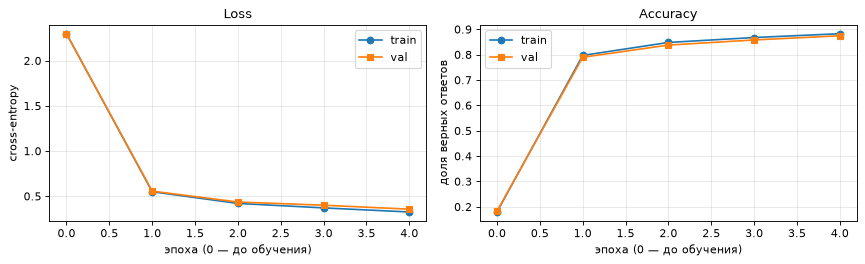

In [8]:
def evaluate(model, X, y, bs=1000):
    model.eval(); tot_loss, correct, preds = 0.0, 0, []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out = model(X[i:i + bs].to(device)); yy = y[i:i + bs].to(device)
            tot_loss += nn.functional.cross_entropy(out, yy, reduction="sum").item()
            preds.append(out.argmax(1).cpu())
    preds = torch.cat(preds)
    return tot_loss / len(X), (preds == y).float().mean().item(), preds

opt = torch.optim.Adam(model.parameters(), lr=LR)
history = [("init",) + evaluate(model, Xtr, ytr)[:2] + evaluate(model, Xva, yva)[:2]]
g = torch.Generator().manual_seed(SEED)
t0 = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    perm = torch.randperm(len(Xtr), generator=g)
    for i in range(0, len(Xtr), BATCH):
        idx = perm[i:i + BATCH]
        loss = nn.functional.cross_entropy(model(Xtr[idx].to(device)), ytr[idx].to(device))
        opt.zero_grad(); loss.backward(); opt.step()
    history.append((epoch,) + evaluate(model, Xtr, ytr)[:2] + evaluate(model, Xva, yva)[:2])
    print(f"epoch {epoch}: train loss {history[-1][1]:.4f} acc {history[-1][2]:.4f} | val loss {history[-1][3]:.4f} acc {history[-1][4]:.4f}")
print(f"время обучения: {time.perf_counter() - t0:.1f} с на {device}")

ep = range(len(history))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(ep, [h[1] for h in history], "o-", label="train"); ax[0].plot(ep, [h[3] for h in history], "s-", label="val")
ax[0].set(title="Loss", xlabel="эпоха (0 — до обучения)", ylabel="cross-entropy"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep, [h[2] for h in history], "o-", label="train"); ax[1].plot(ep, [h[4] for h in history], "s-", label="val")
ax[1].set(title="Accuracy", xlabel="эпоха (0 — до обучения)", ylabel="доля верных ответов"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Шаг 10. Ошибки модели

Матрица ошибок (confusion matrix): строка — истинный класс, столбец — предсказанный. Затем — шесть ошибок, в которых сеть была наиболее уверена.

accuracy по классам:
  T-shirt/top  0.856
  Trouser      0.971
  Pullover     0.815
  Dress        0.880
  Coat         0.850
  Sandal       0.985
  Shirt        0.603
  Sneaker      0.901
  Bag          0.953
  Ankle boot   0.944
самые частые путаницы (истинный → предсказанный: число):
  Shirt        → T-shirt/top : 69
  Shirt        → Coat        : 64
  Pullover     → Coat        : 50
  Shirt        → Pullover    : 48
  T-shirt/top  → Shirt       : 33


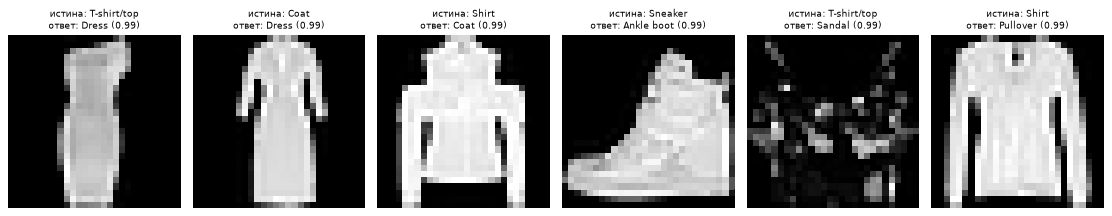

всего ошибок: 628 из 5000


In [9]:
val_loss, val_acc, val_pred = evaluate(model, Xva, yva)
cm = torch.zeros(10, 10, dtype=torch.long)
for t_, p_ in zip(yva, val_pred): cm[t_, p_] += 1
per_class = cm.diag().float() / cm.sum(1)
print("accuracy по классам:")
for k in range(10): print(f"  {CLASSES[k]:12} {per_class[k]:.3f}")
off = cm.clone(); off.fill_diagonal_(0)
print("самые частые путаницы (истинный → предсказанный: число):")
for flat_i in off.flatten().argsort(descending=True)[:5]:
    i, j = divmod(flat_i.item(), 10); print(f"  {CLASSES[i]:12} → {CLASSES[j]:12}: {off[i, j].item()}")

model.eval()
with torch.no_grad():
    probs = torch.softmax(model(Xva.to(device)), 1).cpu()
wrong = (val_pred != yva).nonzero().ravel()
top = wrong[probs[wrong].max(1).values.argsort(descending=True)[:6]]
fig, ax = plt.subplots(1, 6, figsize=(14, 2.8))
for a_, i in zip(ax, top):
    a_.imshow(Xva[i, 0]); a_.axis("off")
    a_.set_title(f"истина: {CLASSES[yva[i]]}\nответ: {CLASSES[val_pred[i]]} ({probs[i].max():.2f})", fontsize=8)
plt.tight_layout(); plt.show()
print(f"всего ошибок: {len(wrong)} из {len(yva)}")

## 5. Неудачный случай: наивный softmax

Формула $p_i=e^{z_i}/\sum_je^{z_j}$, записанная «в лоб», ломается на больших logits. Это не теоретическая возможность: у обученной и уверенной сети logits в десятки и сотни единиц — обычное дело.

In [10]:
def softmax_naive(z):
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

z_big = np.array([[1000.0, 1001.0, 999.0]])
with np.errstate(over="ignore", invalid="ignore"):
    print("наивный softmax :", softmax_naive(z_big))
print("stable softmax  :", softmax_stable(z_big))
print("тот же результат, что для [1, 2, 0]:", softmax_stable(np.array([[1.0, 2.0, 0.0]])))

# вторая ловушка: log(0), когда вероятность правильного класса округлилась до нуля
z_conf = np.array([[0.0, 800.0, 0.0]]); tgt = np.array([0])
with np.errstate(divide="ignore"):
    print("\nуверенная ошибка, logits [0, 800, 0], истина — класс 0:")
    print("  через −log(softmax):", -np.log(softmax_stable(z_conf)[0, 0]))
log_sum_exp = z_conf.max() + np.log(np.exp(z_conf - z_conf.max()).sum())
print("  через log-sum-exp   :", log_sum_exp - z_conf[0, 0], "(= logsumexp(z) − z_y)")
print("  PyTorch             :", nn.functional.cross_entropy(torch.tensor(z_conf), torch.tensor(tgt)).item())

наивный softmax : [[nan nan nan]]
stable softmax  : [[0.2447 0.6652 0.09  ]]
тот же результат, что для [1, 2, 0]: [[0.2447 0.6652 0.09  ]]

уверенная ошибка, logits [0, 800, 0], истина — класс 0:
  через −log(softmax): inf
  через log-sum-exp   : 800.0 (= logsumexp(z) − z_y)
  PyTorch             : 800.0


Наивный вариант даёт `nan`: $e^{1000}$ — `inf`, а `inf/inf` не определено. Стабильный вариант возвращает то же, что для $[1,2,0]$: logits отличаются только общим сдвигом на 999.

Вторая ловушка — даже стабильный softmax может вернуть для правильного класса вероятность, округлённую до нуля, и тогда $-\ln0=\infty$. Правильно считать loss, не проходя через вероятности: $L=\ln\sum_je^{z_j}-z_y$ (log-sum-exp). Именно поэтому `CrossEntropyLoss` в PyTorch принимает **logits**, а не вероятности: softmax и логарифм внутри объединены в одну численно устойчивую операцию.

## 6. Вывод

- **Размерности.** Spatial size меняют только слои со stride > 1: каждый MaxPool делит сторону пополам (28 → 14 → 7). Свёртки с $K=3,P=1,S=1$ размер сохраняют, но меняют число каналов. Формула $\lfloor(H+2P-K)/S\rfloor+1$ дала те же размеры, что PyTorch, для всех слоёв.
- **Параметры.** Ручной расчёт: conv1 — 160, conv2 — 4640, conv3 — 18 496, fc — 31 370; всего 54 666, совпадает с `sum(p.numel())`. Число параметров свёрток растёт с числом каналов ($C_{in}\cdot C_{out}$), а не с размером картинки; полносвязный слой — 57 % всех параметров, потому что соединяет все 3136 входов со всеми выходами.
- **Receptive field.** Для цепочки из вопроса 2 — 10×10 (подтверждено численно по градиенту). Для собственной сети — 18×18 у последней свёртки при картинке 28×28: один элемент последней карты видит большую часть изображения. Stride увеличивает «шаг» $j$ (1 → 2 → 4), и каждый следующий слой расширяет поле быстрее: conv1 добавил 2 пикселя, conv2 — 4, conv3 — 8.
- **Softmax и CE.** Собственная реализация в NumPy совпала с `CrossEntropyLoss` до 5e-8; для необученной сети loss = 2.2976 ≈ ln 10 = 2.3026, как и должно быть при равновероятных классах. Аналитический градиент $(p-y)/B$ совпал с autograd до 4e-10.
- **Обучение.** За 4 эпохи (около 15 с на CPU) loss упал с 2.30 до 0.32 на train и 0.36 на val; accuracy — 0.882 и 0.874. Кривые идут вместе, разрыв меньше одного процентного пункта: сеть не переобучилась и ещё не вышла на плато.
- **Ошибки.** 628 ошибок на 5000 картинок. Хуже всего распознаётся Shirt — 60 %; его путают с T-shirt/top (69 раз), Coat (64) и Pullover (48). Это классы верхней одежды с похожим силуэтом, на картинке 28×28 они отличаются мелкими деталями (воротник, пуговицы, длина рукава). Классы с характерной формой — Trouser (97 %), Sandal (98.5 %), Bag (95 %) — распознаются почти без ошибок.
- **Почему PyTorch принимает logits:** softmax + log по отдельности численно неустойчивы (раздел 5).

## 7. Вопросы на защиту

**1. Как вычисляется output size свёрточного слоя и что делает padding?**
$H_{out}=\lfloor(H+2P-K)/S\rfloor+1$: в расширенной строке длиной $H+2P$ ядро длины $K$ имеет $H+2P-K$ возможных сдвигов, шагом $S$ проходится $\lfloor\cdot/S\rfloor$ из них, плюс стартовая позиция. Padding дописывает по краям $P$ нулей с каждой стороны: без него каждая свёртка 3×3 «съедает» по пикселю с края, а крайние пиксели участвуют в меньшем числе окон. При $K=3,S=1,P=1$ размер сохраняется.

**2. Как receptive field растёт через последовательность слоёв и почему stride ускоряет его рост?**
$r_{new}=r+(K-1)j$, $j_{new}=jS$. Каждый слой добавляет $(K-1)$ шагов текущей сетки. Пока stride равен 1, $j=1$ и поле растёт линейно: +2 на свёртку 3×3. Слой со stride 2 удваивает $j$ — после него та же свёртка добавляет уже +4, после второго — +8. Поэтому pooling/stride позволяют небольшой сети охватить всю картинку.

**3. Ручной softmax/CE; почему перед exp нужно вычитать max(logit).**
`z_shift = z − z.max(axis=1, keepdims=True)`; `e = np.exp(z_shift)`; `p = e / e.sum(...)`; `loss = −log(p[target])`. Вычитание константы не меняет softmax (множитель $e^{-c}$ сокращается), но делает наибольший показатель равным нулю: $\exp$ не переполняется, а знаменатель не меньше 1, то есть деления на ноль тоже нет. Без этого при logits порядка 1000 получается `inf/inf = nan`.